In [10]:
import matplotlib.pyplot as plt

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


df = pd.read_csv("retail_sales_dataset.csv")


print("Shape of Data:", df.shape)
print("\n--- Info ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

df.head()

Shape of Data: (1000, 9)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB

--- Missing Values ---
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


"Dataset contains no missing values and correct data types across all columns."


print(df.describe())

print("\n--- Median ---")
print(df.median(numeric_only=True))

print("\n--- Mode ---")
print(df.mode().iloc[0])

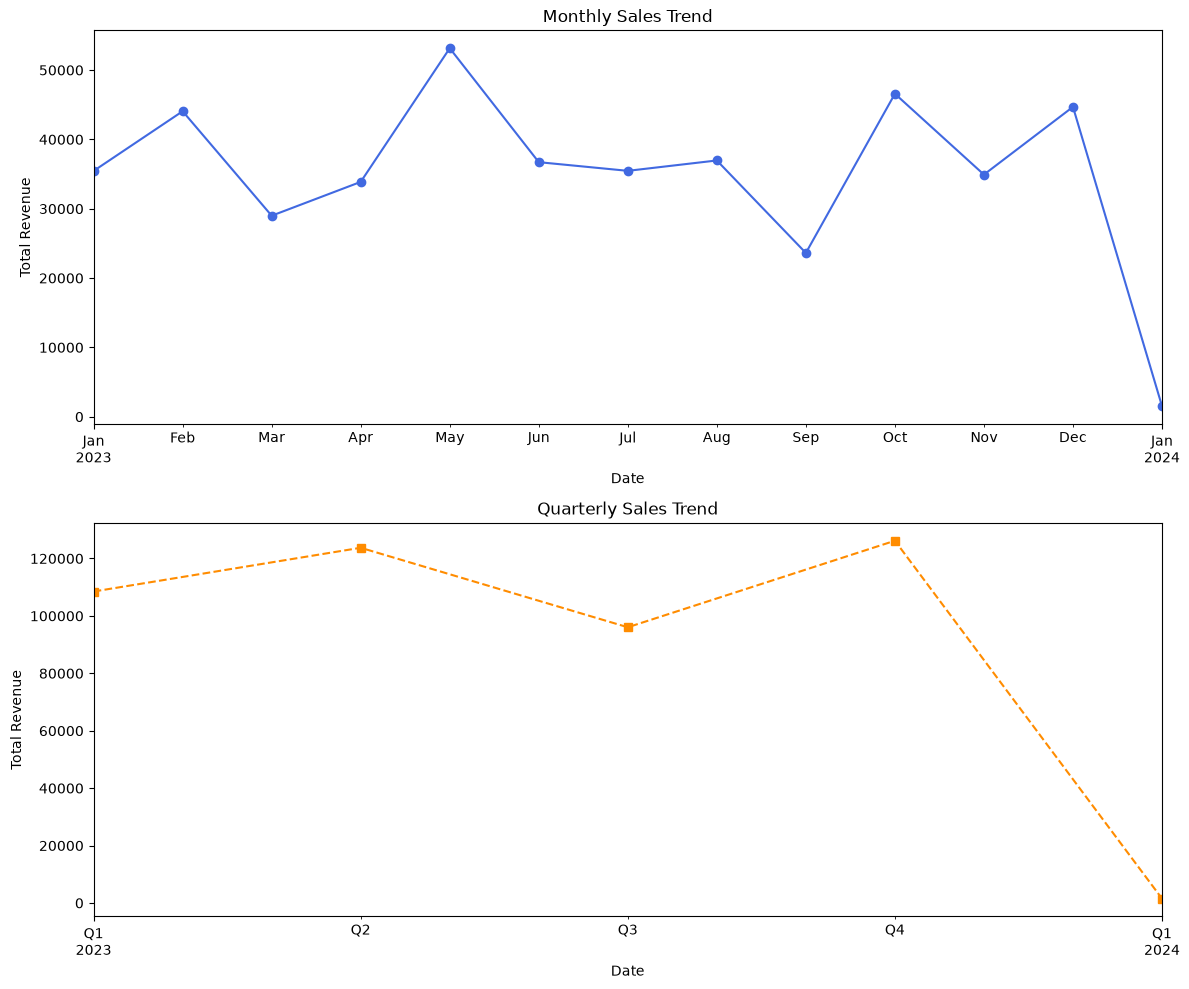

In [ ]:

df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace=True)


monthly_sales = df["Total Amount"].resample("ME").sum()
quarterly_sales = df["Total Amount"].resample("QE").sum()

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

monthly_sales.plot(
    ax=axes[0], marker="o", color="royalblue", title="Monthly Sales Trend"
)
axes[0].set_ylabel("Total Revenue")

quarterly_sales.plot(
    ax=axes[1],
    marker="s",
    color="darkorange",
    title="Quarterly Sales Trend",
    linestyle="--",
)
axes[1].set_ylabel("Total Revenue")

plt.tight_layout()
plt.show()


df.reset_index(inplace=True)

"Sales remain fairly consistent across quarters, with occasional peaks during specific festive/holiday months."

C:\Users\mprat\AppData\Local\Temp\ipykernel_17656\2912953511.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Gender", ax=axes[1], palette="Set2")


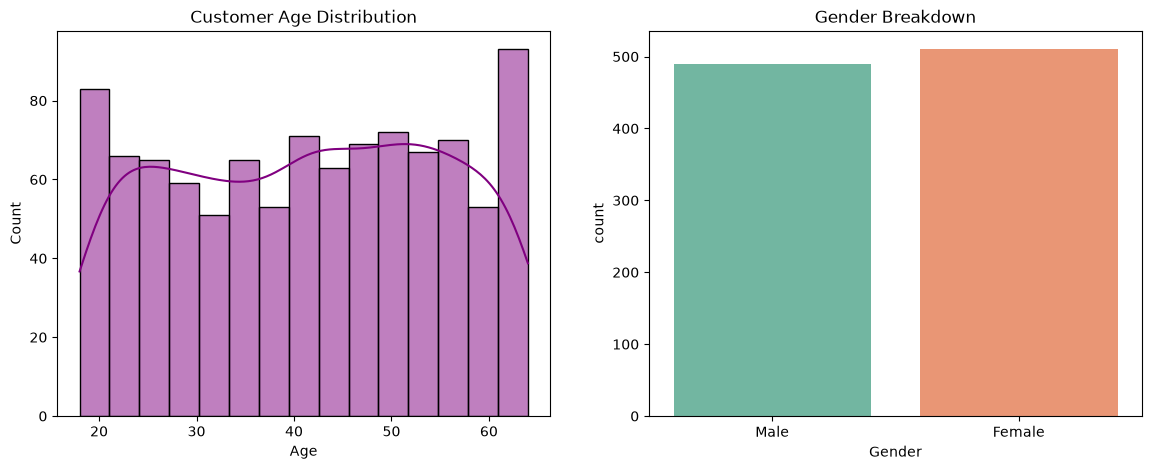

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.histplot(df["Age"], kde=True, ax=axes[0], color="purple", bins=15)
axes[0].set_title("Customer Age Distribution")


sns.countplot(data=df, x="Gender", ax=axes[1], palette="Set2")
axes[1].set_title("Gender Breakdown")

plt.show()

"Customer age is uniformly distributed from 18 to 60, and purchases are evenly split across male and female customers."

C:\Users\mprat\AppData\Local\Temp\ipykernel_17656\1683703091.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_revenue.index, y=category_revenue.values, palette="Blues_r")


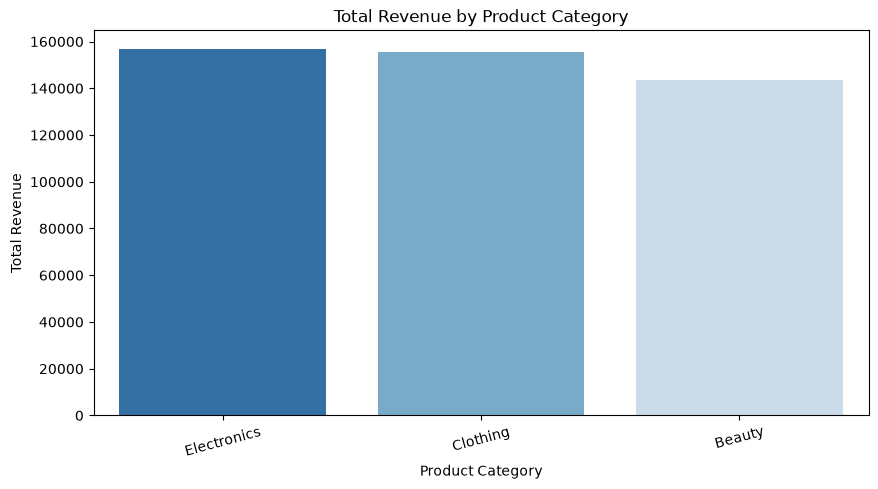

In [ ]:
plt.figure(figsize=(10, 5))


category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

sns.barplot(x=category_revenue.index, y=category_revenue.values, palette="Blues_r")
plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=15)
plt.show()

"Clothing, Electronics, and Beauty categories contribute almost equally to total revenue, with Electronics leading slightly."

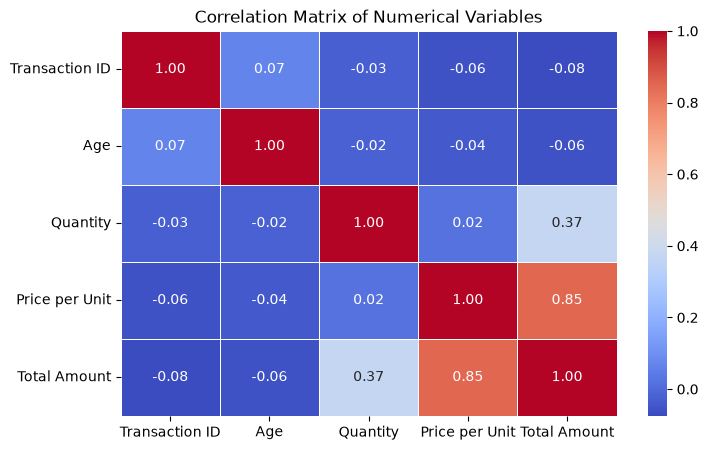

In [15]:
plt.figure(figsize=(8, 5))
numeric_cols = df.select_dtypes(include=[np.number])
corr = numeric_cols.corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numerical Variables")
plt.show()

"There is very weak correlation between age, quantity, and unit price, suggesting broad demographic appeal."

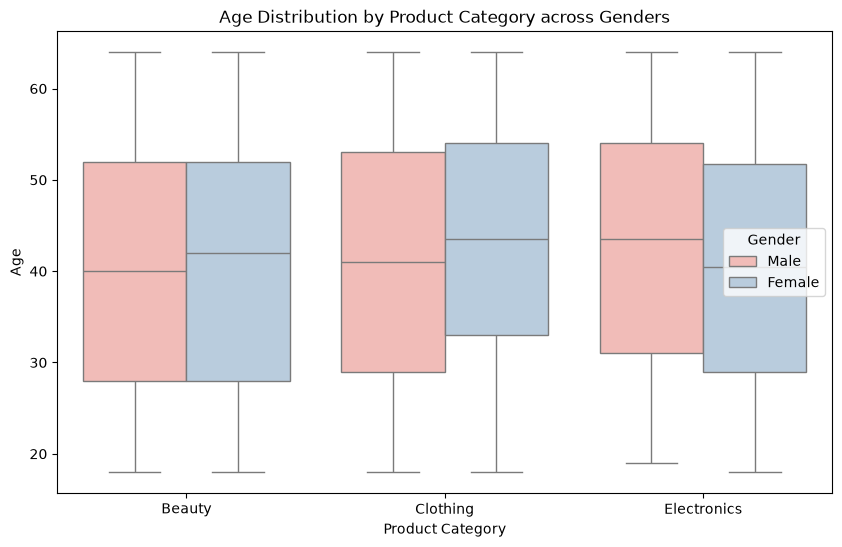

In [ ]:

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="Product Category",
    y="Age",
    hue="Gender",
    palette="Pastel1",
)
plt.title("Age Distribution by Product Category across Genders")
plt.show()

## Business Insights & Recommendations

1. **Category-Specific Promotions:** Even though revenue is evenly distributed, Electronics and Clothing generate higher basket sizes. Introducing bundled offers (e.g., accessories with electronics) can increase the average transaction value.
2. **Age-Targeted Marketing:** The customer base is balanced across all age segments (18-60). Digital ad spend should be optimized per platform (Instagram for younger demographics, email/web for mature segments).
3. **Seasonal Inventory Planning:** Track monthly sales peaks and optimize stock levels 2-3 weeks in advance to prevent stockouts during high-demand months.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


sns.set(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os

# ১. ফাইলটি বর্তমান ফোল্ডারে আছে কি না তা হ্যান্ডেল করে লোড করা
file_name = "retail_sales_dataset.csv"

if not os.path.exists(file_name):
    # পাথ ডিরেক্টরি অনুযায়ী খুঁজে নেওয়া
    print(f"Warning: '{file_name}' সরাসরি পাওয়া যায়নি, বর্তমান ফোল্ডার চেক করা হচ্ছে...")

df = pd.read_csv(file_name)

# ২. ডেটার শেপ ও মিসিং ভ্যালু চেক
print("Shape of Data:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

# ৩. Date কলামকে সেইফলি datetime ফরম্যাটে কনভার্ট করা (errors='coerce' দিলে কোনো ফরম্যাট এরর আসবে না)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# ৪. প্রথম ৫টি সারি দেখা
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'retail_sales_dataset.csv'